# 22 — Golden vector trên tín hiệu kiểm thử số học

> **Phạm vi:** proof of concept phân loại motion phenotype dựa trên proxy label — KHÔNG phải bộ phân loại an toàn hàng hải đã xác thực. Golden vector đã chuẩn bị **không** có nghĩa parity Python/C hay triển khai ESP32 đã được kiểm chứng. Trạng thái: `PYTHON_REFERENCE_READY` · `C_PARITY_PENDING`.

**Mục tiêu.** Trình bày các tín hiệu kiểm thử **toán học** tất định (không phải dữ liệu hàng hải tổng hợp, không dùng để huấn luyện), golden 23 feature do **extractor production** tính, kiểm tra giải tích độc lập, và tính tất định/checksum của fixture.

Notebook không ghi đè fixture đã theo dõi Git: phần kiểm tra tất định sinh lại vào thư mục tạm.

In [1]:
from pathlib import Path
import json, sys, hashlib, math, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/parity/golden.py").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/parity/golden.py").is_file())
sys.path.insert(0, str(REPO_ROOT))
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.unicode_minus": False, "figure.dpi": 100, "font.size": 9})
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
from ml.parity.cases import SYNTHETIC_CASES
from ml.parity.contract import FEATURE_ORDER, feature_settings
from ml.parity.golden import SYNTHETIC_ROOT, MANIFEST, read_inputs, build_suite, verify_manifest
from ml.parity import compare
manifest = json.loads((REPO_ROOT / MANIFEST).read_text(encoding="utf-8"))
expected, cases = compare.load_golden(REPO_ROOT, "synthetic")
print("Case:", len(cases), "| endpoint:", manifest["suites"]["synthetic"]["endpoints"], "| bản ghi golden:", len(expected))

Case: 31 | endpoint: 488 | bản ghi golden: 11224


## 1. Danh mục case và lỗi mà mỗi case nhắm tới

Mỗi case được thiết kế để một lỗi hiện thực cụ thể tạo sai lệch vượt dung sai: đơn vị, thứ tự, nội suy phân vị, biên cửa sổ, quy ước phương sai, dấu, chia cho 0, coverage/gap, warm-up.

In [2]:
catalog = pd.DataFrame([{"case_id": c["case_id"], "mô tả": c["title"], "phát hiện": ", ".join(c["detects"]), "mẫu": c["n_samples"],
                         "endpoint": c["endpoint_count"], "NaN/Inf roll": c["non_finite_samples"]["roll"],
                         "timestamp bỏ": c["dropped_timestamps"]} for c in cases.values()])
display(catalog)

,case_id,mô tả,phát hiện,mẫu,endpoint,NaN/Inf roll,timestamp bỏ
0,SYN01_const_zero,Roll/Pitch hằng 0,"division_by_zero, undefined_status, sign_zero",2101,16,0,0
1,SYN02_const_roll_pos,Roll hằng +3°,"offset_sign, zero_variance, r2_undefined",2101,16,0,0
2,SYN03_const_roll_neg_pitch_pos,"Roll hằng -2.5°, Pitch hằng +1.25°","sign_handling, mean_abs",2101,16,0,0
3,SYN04_sine_roll,"Roll sin 5°, 0.1 Hz, số chu kỳ nguyên","variance_convention, diff_rms, sign_ratio_half",2101,16,0,0
4,SYN05_sine_pitch,"Pitch sin 2°, 0.2 Hz","pitch_channel, feature_order",2101,16,0,0
5,SYN06_mixed_order_detector,Roll/Pitch hỗn hợp: 23 giá trị đôi một khác nhau,"feature_order, units, channel_swap",2101,16,0,0
6,SYN07_growing_amplitude,Biên độ Roll tăng tuyến tính,"trend_slope, ratio",2101,16,0,0
7,SYN08_decreasing_amplitude,Biên độ Roll giảm tuyến tính,"negative_slope, ratio_below_one",2101,16,0,0
8,SYN09_block_step_linear,"Biên độ theo block 1, 2, 3 (R² = 1)","block_boundaries, trend_units, r2_one",2101,16,0,0
9,SYN10_block_step_nonlinear,"Biên độ theo block 1, 3, 2 (R² = 0.25)","r2_formula, block_order",2101,16,0,0


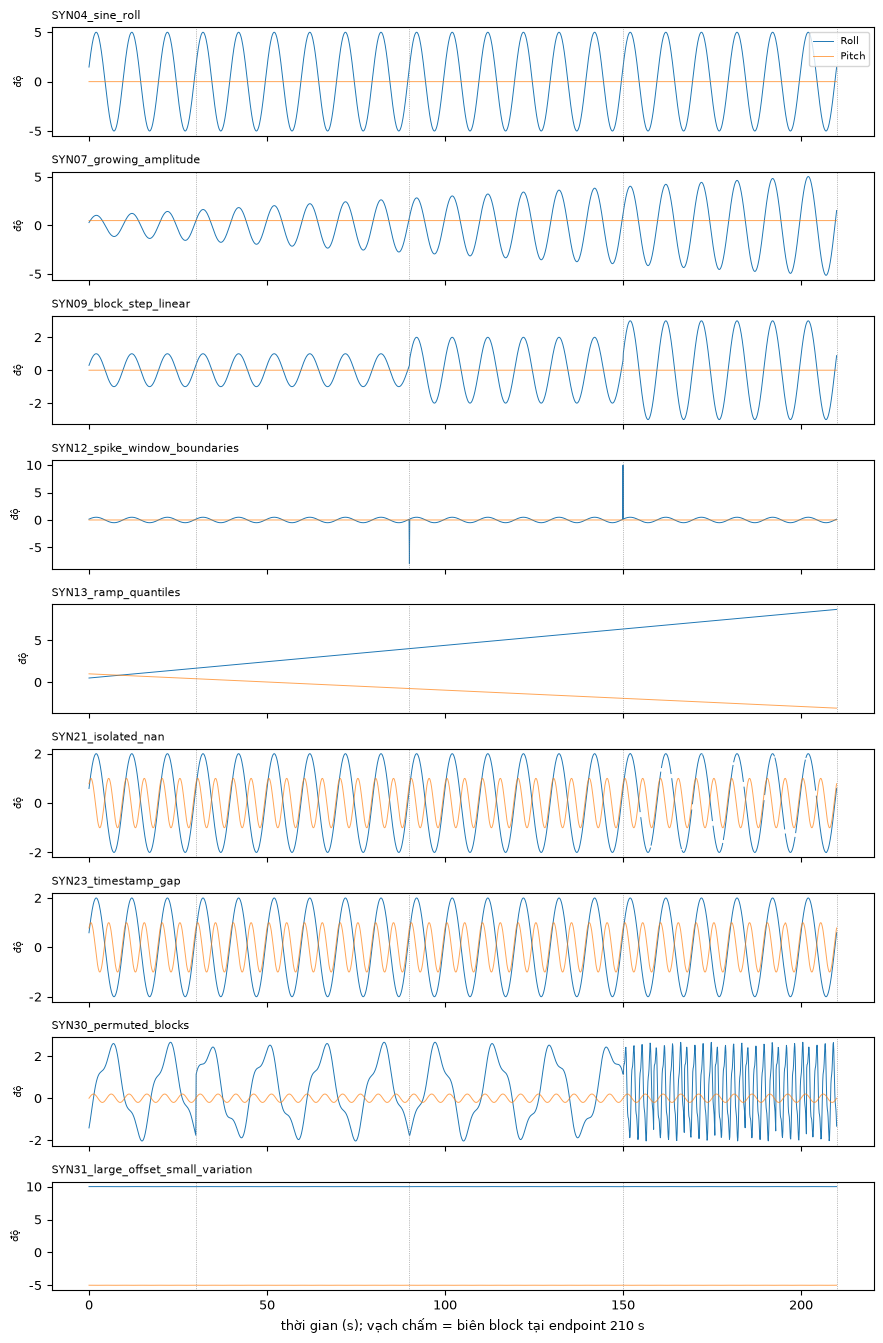

In [3]:
show = ["SYN04_sine_roll", "SYN07_growing_amplitude", "SYN09_block_step_linear", "SYN12_spike_window_boundaries",
        "SYN13_ramp_quantiles", "SYN21_isolated_nan", "SYN23_timestamp_gap", "SYN30_permuted_blocks", "SYN31_large_offset_small_variation"]
fig, axes = plt.subplots(len(show), 1, figsize=(9, 1.5 * len(show)), sharex=True)
for ax, cid in zip(axes, show):
    d = read_inputs(REPO_ROOT / cases[cid]["input_file"])
    ax.plot(d.time_seconds, d.roll_deg, lw=0.7, label="Roll")
    ax.plot(d.time_seconds, d.pitch_deg, lw=0.7, alpha=0.7, label="Pitch")
    for b in (30, 90, 150, 210): ax.axvline(b, color="grey", lw=0.5, ls=":")
    ax.set_ylabel("độ", fontsize=7); ax.set_title(cid, fontsize=8, loc="left")
axes[0].legend(fontsize=7, loc="upper right"); axes[-1].set_xlabel("thời gian (s); vạch chấm = biên block tại endpoint 210 s")
plt.tight_layout(); plt.show()

## 2. Golden tại endpoint cuối

Bảng dưới là vector 23 phần tử (theo thứ tự contract) tại endpoint cuối của mỗi case. Ô trống = feature không VALID (giá trị `null`, **không phải 0**).

,roll_rms_60,roll_std_60,roll_mean_60,roll_peak_to_peak_60,roll_abs_p95_60,roll_abs_max_60,roll_iqr_60,roll_diff_rms_60,roll_mean_180,roll_median_180,...,roll_mean_shift_180,roll_rms_early_60,roll_rms_late_60,roll_rms_ratio_180,roll_rms_slope_180,roll_rms_trend_r2_180,roll_p95_trend_slope_180,pitch_rms_60,pitch_std_60,pitch_peak_to_peak_60
case_id,,,,,,,,,,,,,,,,,,,,,
SYN01_const_zero,0,0,0,0,0,0,0,0,0,0,...,0,0,0,,0,,0,0,0,0
SYN02_const_roll_pos,3,0,3,0,3,3,0,0,3,3,...,0,3,3,1,0,,0,0,0,0
SYN03_const_roll_neg_pitch_pos,2.5,0,-2.5,0,2.5,2.5,0,0,-2.5,-2.5,...,0,2.5,2.5,1,0,,0,1.25,0,0
SYN04_sine_roll,3.53553,3.53553,0,9.999,4.98519,4.9995,7.00901,0.221961,0,0,...,0,3.53553,3.53553,1,0,,0,0,0,0
SYN05_sine_pitch,0,0,0,0,0,0,0,0,0,0,...,0,0,0,,0,,0,1.41421,1.41421,3.99984
SYN06_mixed_order_detector,2.57727,2.24831,1.25993,7.754,5.10033,5.50773,3.90813,0.16294,1.1648,1.14245,...,0.171567,2.41225,2.57727,1.06841,0.082509,0.999881,0.190029,1.14263,1.07842,3.38985
SYN07_growing_amplitude,3.25566,3.25552,-0.0301038,10.179,4.82371,5.13948,6.4137,0.205259,-0.0301038,-0.000707939,...,-4.93601e-10,1.56858,3.25566,2.07555,0.843541,0.999999,1.16665,0.5,0,0
SYN08_decreasing_amplitude,1.72073,1.72047,0.0301038,5.81942,2.70954,2.9597,3.277,0.10717,0.0301038,0.000707939,...,-3.5887e-09,3.40911,1.72073,0.504745,-0.84419,0.999999,-1.15809,0.5,0,0
SYN09_block_step_linear,2.12132,2.12132,0,5.9994,2.99111,2.9997,4.2054,0.133177,0,0,...,0,0.707107,2.12132,3,0.707107,1,0.997038,0,0,0


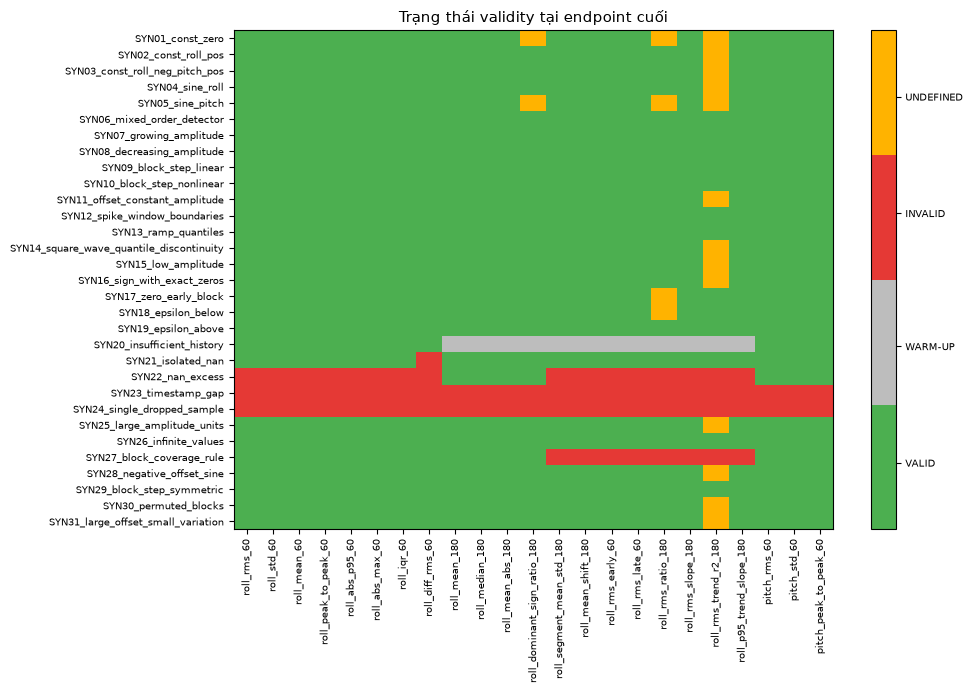

bản ghi
status                   reason_code                           
INSUFFICIENT_WINDOW      WINDOW_HISTORY_SHORT              4440
INVALID_INPUT            ADJACENT_PAIR_COVERAGE               2
                         SEGMENT_BLOCK_COVERAGE              64
                         SIGNAL_VALID_COVERAGE               80
                         TIMESTAMP_GAP                       46
UNDEFINED_MATHEMATICALLY CONSTANT_RMS_TREND                  53
                         EARLY_RMS_AT_OR_BELOW_EPSILON       16
                         NON_FINITE_RESULT                    8
VALID                                                      6515

In [4]:
last = expected.loc[expected.endpoint_index == expected.groupby("case_id").endpoint_index.transform("max")]
wide = last.pivot(index="case_id", columns="feature_index", values="value")
wide.columns = [FEATURE_ORDER[i] for i in wide.columns]
display(wide.map(lambda v: "" if v is None else f"{v:.6g}"))
status = last.pivot(index="case_id", columns="feature_index", values="status")
codes = {"VALID": 0, "INSUFFICIENT_WINDOW": 1, "INVALID_INPUT": 2, "UNDEFINED_MATHEMATICALLY": 3}
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(status.replace(codes).astype(int).to_numpy(), cmap=plt.matplotlib.colors.ListedColormap(["#4caf50", "#bdbdbd", "#e53935", "#ffb300"]), aspect="auto")
ax.set_yticks(range(len(status))); ax.set_yticklabels(status.index, fontsize=7)
ax.set_xticks(range(23)); ax.set_xticklabels(FEATURE_ORDER, rotation=90, fontsize=7)
cb = fig.colorbar(im, ticks=[0.4, 1.1, 1.9, 2.6]); cb.ax.set_yticklabels(["VALID", "WARM-UP", "INVALID", "UNDEFINED"], fontsize=7)
ax.set_title("Trạng thái validity tại endpoint cuối"); plt.tight_layout(); plt.show()
display(expected.groupby(["status", "reason_code"]).size().rename("bản ghi").to_frame())

## 3. Kiểm tra giải tích độc lập (Level 1)

`ml/parity/analytic.py` suy ra đáp án bằng công thức đóng, **không** import extractor. Ví dụ:

- Sine biên độ $A$, số chu kỳ nguyên: RMS = std quần thể = $A/\sqrt2$, mean = 0.
- Sai phân của sine: $d_k = 2A\sin(\Delta/2)\cos\theta_{k-1/2}$; cửa sổ 600 mẫu chỉ có **599** cặp, nên $\mathrm{RMS}_d = 2A\sin(\Delta/2)\sqrt{1/2-\cos(2\theta_{1500.5})/(2\cdot599)}$.
- Ramp bước $s$: Type-7 $Q_{0.95} = x_{\min}+0.95\cdot599\,s$; median 180 s $= x_{\min}+0.5\cdot1799\,s$.
- RMS block $(1,2,3)/\sqrt2 \Rightarrow R^2=1$; $(1,3,2)/\sqrt2 \Rightarrow R^2=(r_3-r_1)^2/(2\,SST)=0.25$; $(1,2,1)/\sqrt2 \Rightarrow R^2=0$ (VALID, khác UNDEFINED).

In [5]:
checks = pd.DataFrame([c for case in json.loads((REPO_ROOT / SYNTHETIC_ROOT / "cases.json").read_text())["cases"] for c in case["analytic_checks"]])
print(f"Đạt {int(checks.passed.sum())}/{len(checks)}")
display(checks[["case_id", "feature", "expected", "golden", "abs_diff", "tolerance", "passed", "derivation"]])

Đạt 123/123


,case_id,feature,expected,golden,abs_diff,tolerance,passed,derivation
0,SYN01_const_zero,roll_rms_60,0.0,0.0,0.0,1.000000e-09,True,tín hiệu hằng 0
1,SYN01_const_zero,roll_std_60,0.0,0.0,0.0,1.000000e-09,True,tín hiệu hằng 0
2,SYN01_const_zero,roll_mean_60,0.0,0.0,0.0,1.000000e-09,True,tín hiệu hằng 0
3,SYN01_const_zero,roll_peak_to_peak_60,0.0,0.0,0.0,1.000000e-09,True,tín hiệu hằng 0
4,SYN01_const_zero,roll_abs_p95_60,0.0,0.0,0.0,1.000000e-09,True,tín hiệu hằng 0
...,...,...,...,...,...,...,...,...
118,SYN30_permuted_blocks,roll_rms_slope_180,0.0,0.0,0.0,5.333390e-06,True,RMS 3 block bằng nhau
119,SYN30_permuted_blocks,roll_mean_shift_180,0.0,0.0,0.0,5.333390e-06,True,mean bằng nhau
120,SYN30_permuted_blocks,roll_segment_mean_std_180,0.0,0.0,0.0,5.333390e-06,True,mean bằng nhau
121,SYN30_permuted_blocks,roll_p95_trend_slope_180,0.0,0.0,0.0,5.333390e-06,True,P95 của cùng tập giá trị


## 4. Tính tất định và checksum

Sinh lại toàn bộ suite synthetic vào một thư mục tạm và so SHA-256 với manifest. Input lưu dưới dạng chuỗi float32 ngắn nhất round-trip nên C đọc bằng `strtof` được đúng cùng bit.

In [6]:
with tempfile.TemporaryDirectory() as tmp:
    rebuilt = build_suite(Path(tmp), "synthetic", feature_settings(REPO_ROOT))
same = {p: manifest["files"][p]["sha256"] == h for p, h in rebuilt["files"].items()}
print("File sinh lại:", len(same), "| trùng checksum:", sum(same.values()))
print("Kiểm tra manifest:", {k: v for k, v in verify_manifest(REPO_ROOT, include_untracked=False).items() if k != "problems"})
tracked = {p: e for p, e in manifest["files"].items() if e["tracked_in_git"]}
print(f"File theo dõi Git: {len(tracked)}, tổng {sum(e['bytes'] for e in tracked.values())/1e6:.2f} MB")

File sinh lại: 34 | trùng checksum: 34
Kiểm tra manifest: {'files': 44, 'passed': True}
File theo dõi Git: 36, tổng 4.27 MB


## Diễn giải

- Có 31 case phủ đúng danh sách yêu cầu: hằng 0/khác 0, offset dương/âm, sine Roll/Pitch, hỗn hợp, biên độ tăng/giảm, biên độ không đổi có offset, gai, ranh giới phân vị, biên độ rất nhỏ, đổi dấu, R² = 1/0,25/0/UNDEFINED, thiếu lịch sử, NaN, Inf, gap timestamp, quy tắc block (C01), SST bằng 0 chính xác (C03), offset lớn với dao động nhỏ.
- Kiểm tra giải tích độc lập đều đạt; golden được tạo lại byte-giống-hệt.
- SYN06 có 22 giá trị phân biệt (vì `roll_rms_late_60 = roll_rms_60`, C06), nên đảo vị trí gần như mọi cặp feature đều bị phát hiện.

## Hạn chế

- Các đáp án giải tích chỉ có cho một phần case/feature; phần còn lại dựa vào extractor đã được test.
- Tín hiệu kiểm thử là toán học, không đại diện cho phân phối chuyển động tàu.

## Ghi chú vấn đáp

- *Tại sao làm tròn input về float32 trước?* Để sai lệch do đầu vào không lẫn với sai lệch do thuật toán khi so với C float32.
- *Tại sao sai phân có 599 cặp?* Cặp nối mẫu ngay trước cửa sổ với mẫu đầu cửa sổ bị loại vì mẫu trước nằm ngoài $(t-60,t]$.
- *Vì sao cần SYN31?* Phương sai một lượt $E[x^2]-E[x]^2$ trong float32 chỉ hỏng rõ khi offset lớn so với dao động; các case khác không lộ lỗi này.